[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/00-kiwi-dicom-to-nifti.ipynb)

# From Scanner Slices to 3D AI Tensors: Converting the 7T Kiwi DICOM Series to NIfTI & BIDS

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Kiwi Challenge Notebook Sequence (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 0. **`00-kiwi-dicom-to-nifti.ipynb` (this notebook)** — History of medical image formats (`XITE/BIFF` → `DICOM` → `NIfTI` & `BIDS`), reading 128 Bruker 7T DICOM slices, avoiding 3 classic geometry bugs, and converting `DICOM → NIfTI`
> 1. [`01-kiwi-explore.ipynb`](./01-kiwi-explore.ipynb) — 3D NIfTI headers, physical voxel geometry & affine coordinate systems
> 2. [`02-kiwi-seeds-explore.ipynb`](./02-kiwi-seeds-explore.ipynb) — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. [`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb) — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
> 4. [`03b-kiwi-interactive-gt-and-interrater.ipynb`](./03b-kiwi-interactive-gt-and-interrater.ipynb) — Interactive 3D Jupyter-Widget delineation, personalized Ground Truth (`MyStuff/`), **Inter-Rater Variability**, **Panoptic Quality ($\text{PQ}$)** & **STAPLE Consensus**
> 5. [`04-kiwi-semantic-vs-instance.ipynb`](./04-kiwi-semantic-vs-instance.ipynb) — Formal definitions of **Semantic, Instance & Panoptic** segmentation and **3D PyTorch Semantic vs. Instance U-Nets**
> 6. [`05-kiwi-promptable-foundation-models.ipynb`](./05-kiwi-promptable-foundation-models.ipynb) — Live **`SAM 2.1` vs. `MedSAM`** foundation-model workshop + 3D slice memory *([guide](../docs/promptable-foundation-models.md) | [PDF](../docs/promptable-foundation-models.pdf))*
> 7. [`06-kiwi-frontier-ai-paradigms.ipynb`](./06-kiwi-frontier-ai-paradigms.ipynb) — Frontier AI capstone: **3D SSL**, **`3D U-Mamba`**, **Conditional Diffusion**, & **Differentiable Neurosymbolic AI (`LTN`)** *([guide](../docs/frontier-ai-paradigms.md) | [PDF](../docs/frontier-ai-paradigms.pdf))*

---

## Learning Outcomes & Biomedical Imaging Glossary

### Learning Objectives (MSc & PhD Biomedical Curriculum)
- **MSc Core Competencies:**
  1. **Clinical vs. Research Image Formats:** Explain why hospital scanners and PACS archives store 2D slices in **DICOM** (`LPS` coordinates, rich clinical/patient tags), whereas quantitative 3D/4D analysis and deep learning use **NIfTI (`.nii.gz`) + BIDS (`.json`)** (`RAS+` coordinates, de-identified header).
  2. **Header Inspection & Spin Physics:** Read hexadecimal `(group, element)` DICOM tags with `pydicom`, identify Protected Health Information (`Group 0010`) under GDPR, and recover static magnetic field strength $B_0$ from the $^1\text{H}$ Larmor frequency $f_0$.
  3. **Safe 3D Volume Conversion:** Avoid the three silent DICOM-to-NIfTI bugs (alphabetical filename sorting, the `np.eye(4)` dummy-affine volume distortion, and `LPS` vs. `RAS+` axis flips) using `SimpleITK` and `dcm2niix`.
- **PhD & Research-Track Extensions:**
  1. **Exact Homogeneous Affine Synthesis:** Derive the $4\times 4$ `RAS+` affine matrix $\mathbf{A}_{\text{RAS}}$ directly from `ImageOrientationPatient` direction cosines, `ImagePositionPatient`, and `PixelSpacing`, and prove why voxel volume equals $|\det(\mathbf{A}_{3\times 3})|$.
  2. **Storage-Order Gauge Invariance:** Prove mathematically why flipping array rows on disk (`LAS` vs. `LPS`) while updating the affine origin and column step leaves the continuous physical world field $I(\mathbf{x}_{\text{mm}})$ strictly invariant.

### Glossary of Medical Image Format & Acquisition Concepts

| Term / Symbol | Intuitive Meaning | Rigorous Mathematical / Technical Definition | Clinical Radiology / AI Relevance |
| :--- | :--- | :--- | :--- |
| **DICOM `(gggg,eeee)` & `VR`** | Labeled key-value fields inside every scanner slice | Standardized 16-bit `(group, element)` hex tag + 2-char **Value Representation** (`DS` decimal string, `US` uint16, `PN` person name) | Universal hospital PACS & scanner interoperability (`DICOM 3.0`) |
| **PHI (`Group 0010`)** | Patient-identifying header fields | Direct identifiers (`PatientName`, `PatientID`, `PatientBirthDate`, exact `StudyDate`) regulated by GDPR / HIPAA | Must be stripped or pseudonymized before research sharing or cloud AI training |
| **Larmor Frequency ($f_0$)** | Precession rate of $^1\text{H}$ spins in a magnetic field | $f_0 = \frac{\gamma}{2\pi} B_0$, with $\frac{\gamma_{^1\text{H}}}{2\pi} = 42.577478\text{ MHz/T}$ | Determines RF resonance (`63.9 MHz` at `1.5 T`, `127.7 MHz` at `3 T`, `300.4 MHz` at `7 T`) |
| **`RARE` / `FSE` (`ETL = 8`)** | Fast spin-echo $T_2$-weighted pulse sequence | **Rapid Acquisition with Relaxation Enhancement** (*Hennig, 1986*): 8 $180^\circ$ refocusing pulses per `TR` fill 8 $k$-space lines | Workhorse clinical $T_2$-weighted brain, spine, and pelvic MRI sequence |
| **Direction Cosines (`IOP`)** | 3D compass vectors for image columns and rows | Six-tuple $[\hat{r}_x,\hat{r}_y,\hat{r}_z,\hat{c}_x,\hat{c}_y,\hat{c}_z]$ of unit vectors in `LPS` space; slice normal $\hat{\mathbf{n}} = \hat{\mathbf{r}} \times \hat{\mathbf{c}}$ | Essential for oblique cardiac/brain slices and physical slice sorting |
| **`LPS` vs. `RAS+`** | Opposite sign conventions for $x$ and $y$ world axes | `LPS`: $+x=\text{Left}, +y=\text{Post.}, +z=\text{Sup.}$; `RAS+`: $+x=\text{Right}, +y=\text{Ant.}, +z=\text{Sup.}$ ($\mathbf{D}=\text{diag}(-1,-1,+1)$) | Confusing them mirrors left/right anatomy or misaligns multi-modal registrations |
| **Homogeneous $4\times 4$ Affine ($\mathbf{A}$)** | Single matrix combining scaling, rotation, and shift | Maps discrete voxel index $\mathbf{i}=[i,j,k,1]^\top$ to world mm $\mathbf{x}_{\text{RAS}}=\mathbf{A}\mathbf{i}$; voxel volume $= \lvert\det(\mathbf{A}_{3\times 3})\rvert$ | Preserves true $\text{mm}^3$ organ/lesion volumes across `nibabel`, `MONAI`, & `3D Slicer` |

---

## 1. Why Convert? Two Worlds of Biomedical Imaging (and How We Got Here)

Inside [`../data/`](../data/), the 2005 7 Tesla kiwifruit MRI scan is stored in **two different representations**:
1. **[`data/dicom/`](../data/dicom/)** — **128 separate files** (`im001` … `im128`), directly exported from the preclinical **Bruker Pharmascan 7T** console at the University of Bergen.
2. **[`data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz`](../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz)** + **[`.json`](../data/kiwi_20050217191129_131073_RARE_high_res_axial.json)** — **one compressed 3D NIfTI volume** plus a **JSON metadata sidecar**, used by Notebooks `01`–`04`, `PyTorch`/`MONAI`, `ITK-SNAP`, and `3D Slicer`.

Why don't hospital scanners simply output NIfTI, or why don't AI pipelines simply train directly on folders of DICOM slices? Because **clinical care** and **computational research** optimize for very different goals:

| Feature | **DICOM** (*Scanner & Hospital PACS*) | **NIfTI (`.nii.gz`) + BIDS (`.json`)** (*Research & 3D AI*) |
| :--- | :--- | :--- |
| **Primary goal** | Safe clinical diagnosis, patient identity, PACS archival & hospital interoperability | Fast 3D/4D tensor math, registration, segmentation & reproducible data sharing |
| **File layout** | Typically **1 file per 2D slice** (`128` files for one 3D scan; thousands for 4D fMRI/DCE-MRI) | **1 compressed file** per 3D/4D scan (`.nii.gz`) + optional `.json` sidecar |
| **Metadata** | Hundreds of `(group, element)` tags: patient name/ID/DOB, scanner physics (`TR`, `TE`), slice pose | Minimal **348-byte binary header** (dimensions, dtype, voxel zooms, $4\times 4$ affine); sequence physics saved in `.json` |
| **Privacy (GDPR / HIPAA)** | **Contains Protected Health Information (PHI)** by design (`PatientName`, `PatientID`, `StudyDate`, …) | **Strips patient identity tags**, separating raw voxel geometry from clinical identity |
| **3D world axes** | **`LPS`** ($+x=\text{Left}$, $+y=\text{Posterior}$, $+z=\text{Superior}$) | **`RAS+`** ($+x=\text{Right}$, $+y=\text{Anterior}$, $+z=\text{Superior}$) |

---

### A Short History: From Raw 12-Bit Scanner Tapes to `DICOM`, `NIfTI`, and `BIDS`

Understanding *why* `DICOM` and `NIfTI` look the way they do is much easier when you see the problems researchers faced before them:

1. **The Pre-Standard Era (1980s – early 1990s): Proprietary Vendor Files & Custom C Code**  
   Early CT and MRI scanners from Siemens, GE, Philips, and Bruker stored images in incompatible vendor-specific binary layouts, with custom header offsets, big-endian vs. little-endian byte ordering across Unix workstations, and 12-bit pixel packing.
   > **Historical Side Note — Early 1.0 T fMRI at Haukeland University Hospital (1992–1995):**  
   > In one of our early functional MRI studies of human primary visual cortex on a conventional **1.0 Tesla Siemens Magnetom Impact** scanner installed at Haukeland University Hospital in 1992 ([Lundervold et al., *International Journal of Neuroscience*, 1995](https://www.tandfonline.com/doi/abs/10.3109/00207459509004883)), no standardized Python/`nibabel`/`SimpleITK` stack existed yet. After transferring the raw **12-bit/pixel** (`0..4095`) scanner frames to a Unix workstation, we used **C programs** and the **[XITE](https://www.mn.uio.no/ifi/english/research/groups/dsb/resources/software/xite/)** library (*X-based Image processing Tools and Environment*, developed at the Department of Informatics, University of Oslo; Lønnestad & Milvang, 1992 — see the [XITE User's Manual (PDF)](https://www.mn.uio.no/ifi/english/research/groups/dsb/resources/software/xite/usersmanual.pdf)) to:
   > - unpack the 12-bit scanner data into XITE's **BIFF** (*Blindern Image File Format*) 16-bit unsigned short representation (`<filename>.us`),
   > - inspect images and run magnified cine-loops in X11 using **`xshow`** (crucial for catching subtle 1–2 mm head-motion artifacts synchronized with the 8 Hz visual flicker!), and
   > - perform $256\times 256 \to 128\times 128$ anatomical-functional co-registration and time-intensity analysis in **C** and **MATLAB 4.0**.
   >
   > Every lab in the world had to maintain similar home-grown conversion scripts whenever a scanner software upgrade changed a binary header!

2. **`ACR-NEMA` (1985, 1988) → `DICOM 3.0` (1993): Clinical Interoperability**  
   The American College of Radiology (ACR) and the National Electrical Manufacturers Association (NEMA) teamed up to ensure any hospital PACS viewer could read images from any vendor's scanner. **DICOM 3.0 (1993)** standardized both the **network protocol** and **self-describing `(group, element)` data dictionaries**, including explicit 3D patient-space coordinates (`ImagePositionPatient` and `ImageOrientationPatient` in millimeters).

3. **Mayo Clinic `Analyze 7.5` (late 1980s – 1990s): The First Neuroimaging Workhorse — and Its Left/Right Bug**  
   Neuroimaging tools (`SPM`, `FSL`, `AFNI`) needed 3D/4D arrays rather than hundreds of 2D DICOM files. Mayo Clinic's `Analyze 7.5` paired a `348-byte` `.hdr` file with a raw `.img` voxel array — **but lacked a full 3D orientation matrix**. Different labs stored voxels Left-to-Right (*radiological*) vs. Right-to-Left (*neurological*), silently flipping left and right brain hemispheres when files moved between tools!

4. **`NIfTI-1` (2003–2004): Fixing 3D Orientation with the $4\times 4$ Affine**  
   Convened by the NIH, the *Neuroimaging Informatics Technology Initiative* (**NIfTI**) kept Analyze's compact `348-byte` header size for backward compatibility, fused header + voxels into a single `.nii` (or gzipped `.nii.gz`) file, and placed **explicit 3D coordinate transforms** (`qform` quaternion and `sform` $4\times 4$ affine matrix) mapping voxel indices $(i, j, k)$ unambiguously into **`RAS+` physical millimeters**.

5. **`BIDS` (2016) & `dcm2niix`: Putting Sequence Physics Back Together**  
   Because NIfTI's 348-byte header has no fields for `EchoTime (TE)`, `RepetitionTime (TR)`, `FlipAngle`, or phase-encoding direction, the **Brain Imaging Data Structure ([BIDS](https://bids.neuroimaging.io/))** standard (Gorgolewski et al., 2016) and Chris Rorden's **[`dcm2niix`](https://github.com/rordenlab/dcm2niix)** converter pair every `.nii.gz` volume with a human-readable **`.json` sidecar** containing non-identifying acquisition physics.

---

## 2. Environment Setup & Reading Raw 2005 Bruker DICOM Slices

Let's load `pydicom`, `nibabel`, and `SimpleITK` (all included in the `bmed365-2027` `uv` environment; auto-installed below if you open this notebook in Google Colab) and locate our 128 DICOM slices in `data/dicom/`.

In [1]:
%matplotlib inline

import concurrent.futures
import json
import pathlib
import subprocess
import sys
import tempfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for pkg_import, pip_name in [
    ("pydicom", "pydicom"),
    ("nibabel", "nibabel"),
    ("SimpleITK", "SimpleITK"),
]:
    try:
        __import__(pkg_import)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import pydicom
import nibabel as nib
import SimpleITK as sitk

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"


def resolve_kiwi_file(rel_path: str) -> pathlib.Path:
    """Locate an asset or data file locally, or download it automatically in Google Colab."""
    for candidate in (
        pathlib.Path("..") / rel_path,
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path(rel_path),
    ):
        if candidate.exists():
            return candidate
    dst = pathlib.Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst


def resolve_kiwi_dicom_dir() -> pathlib.Path:
    """Locate the 128-slice data/dicom/ folder locally, or download it in parallel in Google Colab."""
    for candidate in (
        pathlib.Path("../data/dicom"),
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge/data/dicom"),
        pathlib.Path("data/dicom"),
    ):
        if candidate.is_dir() and len(list(candidate.glob("im*"))) == 128:
            return candidate

    dst_dir = pathlib.Path("data/dicom")
    dst_dir.mkdir(parents=True, exist_ok=True)
    slice_names = [f"im{k:03d}" for k in range(1, 129)]
    missing = [name for name in slice_names if not (dst_dir / name).exists()]
    if missing:
        print(f"Downloading {len(missing)} Bruker DICOM slices from GitHub for Colab session...")
        def _fetch(name: str) -> None:
            urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/data/dicom/{name}", dst_dir / name)
        with concurrent.futures.ThreadPoolExecutor(max_workers=16) as pool:
            list(pool.map(_fetch, missing))
    return dst_dir


dicom_dir = resolve_kiwi_dicom_dir()
ref_nifti_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
ref_json_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.json")

dicom_paths = sorted(dicom_dir.glob("im*"))
print(f"DICOM directory : {dicom_dir} ({len(dicom_paths)} slice files: {dicom_paths[0].name} .. {dicom_paths[-1].name})")
print(f"Reference NIfTI : {ref_nifti_path.name}")
print(f"BIDS sidecar    : {ref_json_path.name}")

DICOM directory : ../data/dicom (128 slice files: im001 .. im128)
Reference NIfTI : kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz
BIDS sidecar    : kiwi_20050217191129_131073_RARE_high_res_axial.json


### 2.1 Peeking Inside a Single DICOM Slice (`im001`)

Notice first that the files `im001` … `im128` have **no `.dcm` file extension**! That is completely normal on hospital CDs, PACS exports, and Bruker/Siemens consoles: DICOM identifies files by an internal `DICM` preamble and `(group, element)` hexadecimal tags rather than filename extensions.

Let's inspect key tags across **four tag groups**:
- **Group `(0010, xxxx)` — Subject / Patient Identity** *(Protected Health Information in human scans!)*
- **Group `(0008, xxxx)` — Study, Institution & Scanner Hardware**
- **Group `(0018, xxxx)` — MRI Physics & Pulse Sequence**
- **Group `(0020, xxxx)` & `(0028, xxxx)` — 3D Slice Pose & Pixel Encoding**

In [2]:
ds_sample = pydicom.dcmread(dicom_paths[0])

selected_keywords = [
    # Subject / Patient identity (Group 0010)
    ("Patient / Privacy", "PatientName"),
    ("Patient / Privacy", "PatientID"),
    ("Patient / Privacy", "PatientSex"),
    # Study & Hardware (Group 0008)
    ("Study & Scanner", "StudyDate"),
    ("Study & Scanner", "AcquisitionTime"),
    ("Study & Scanner", "InstitutionName"),
    ("Study & Scanner", "Manufacturer"),
    ("Study & Scanner", "StationName"),
    ("Study & Scanner", "SoftwareVersions"),
    # MRI Physics (Group 0018)
    ("MRI Physics", "Modality"),
    ("MRI Physics", "ProtocolName"),
    ("MRI Physics", "MRAcquisitionType"),
    ("MRI Physics", "ImagedNucleus"),
    ("MRI Physics", "ImagingFrequency"),
    ("MRI Physics", "MagneticFieldStrength"),
    ("MRI Physics", "RepetitionTime"),
    ("MRI Physics", "EchoTime"),
    ("MRI Physics", "EchoTrainLength"),
    ("MRI Physics", "FlipAngle"),
    ("MRI Physics", "NumberOfAverages"),
    ("MRI Physics", "SliceThickness"),
    # 3D Geometry & Pixels (Groups 0020 & 0028)
    ("Geometry & Pixels", "InstanceNumber"),
    ("Geometry & Pixels", "Rows"),
    ("Geometry & Pixels", "Columns"),
    ("Geometry & Pixels", "PixelSpacing"),
    ("Geometry & Pixels", "ImagePositionPatient"),
    ("Geometry & Pixels", "ImageOrientationPatient"),
    ("Geometry & Pixels", "BitsAllocated"),
    ("Geometry & Pixels", "PixelRepresentation"),
]

rows = []
for category, kw in selected_keywords:
    raw_tag = pydicom.datadict.tag_for_keyword(kw)
    tag = pydicom.tag.Tag(raw_tag) if raw_tag is not None else None
    tag_str = f"({tag.group:04X},{tag.element:04X})" if tag is not None else "—"
    elem = ds_sample.get(tag) if tag is not None else None
    vr = elem.VR if elem is not None else "—"
    val = str(elem.value) if elem is not None else "<not present in header>"
    rows.append({"Category": category, "Tag": tag_str, "VR": vr, "Keyword": kw, "Value in im001": val})

df_tags = pd.DataFrame(rows)
display(df_tags)

,Category,Tag,VR,Keyword,Value in im001
0,Patient / Privacy,"(0010,0010)",PN,PatientName,kiwi_20050217
1,Patient / Privacy,"(0010,0020)",LO,PatientID,kiwi_2005
2,Patient / Privacy,"(0010,0040)",CS,PatientSex,F
3,Study & Scanner,"(0008,0020)",DA,StudyDate,20050217
4,Study & Scanner,"(0008,0032)",TM,AcquisitionTime,192648
5,Study & Scanner,"(0008,0080)",LO,InstitutionName,University of Bergen
6,Study & Scanner,"(0008,0070)",LO,Manufacturer,Bruker BioSpin MRI GmbH
7,Study & Scanner,"(0008,1010)",SH,StationName,Pharmascan300
8,Study & Scanner,"(0018,1020)",LO,SoftwareVersions,PV 3.0.2pl1
9,MRI Physics,"(0008,0060)",CS,Modality,MR


### 2.2 Two Biomedical Detective Details in Those Tags!

1. **Where is `MagneticFieldStrength (0018,0087)`? Recovering $B_0$ from the Larmor Equation!**  
   Notice that Bruker ParaVision `3.0.2pl1` left `MagneticFieldStrength` blank — a classic real-world vendor quirk! However, it *did* record `ImagedNucleus = 1H` and `ImagingFrequency = 300.4118959` (in $\text{MHz}$). From nuclear spin physics, the **Larmor precession frequency** of hydrogen protons ($^1\text{H}$) is:

   $$f_0 = \frac{\gamma}{2\pi} B_0, \qquad \text{where } \frac{\gamma_{^1\text{H}}}{2\pi} = 42.577478\text{ MHz/Tesla}$$

   Let's check $B_0 = f_0 \, / \, (\gamma / 2\pi)$ in Python!

2. **Why `PatientName = kiwi_20050217` and `PatientSex = F` Matter for Hospital Privacy:**  
   Scanner consoles require operator entry of subject metadata before starting an acquisition (so our kiwifruit was registered as female!). In a clinical study at Haukeland University Hospital, `(0010,0010) PatientName`, `(0010,0020) PatientID`, `(0010,0030) PatientBirthDate`, and exact `(0008,0020) StudyDate` are **direct personal identifiers** under GDPR and Norwegian health research law. Converting DICOM to **NIfTI + de-identified BIDS JSON** keeps the voxel spacing and `TR`/`TE` physics while leaving `(0010, xxxx)` identity tags behind.

In [3]:
f0_mhz = float(ds_sample.ImagingFrequency)
gyromagnetic_ratio_1h_mhz_per_t = 42.577478  # 1H gyromagnetic ratio (MHz / T)
b0_tesla = f0_mhz / gyromagnetic_ratio_1h_mhz_per_t

print(f"Recorded 1H Larmor frequency f0 : {f0_mhz:.4f} MHz")
print(f"Computed static field strength  : B0 = {b0_tesla:.3f} Tesla  (~7 T Bruker Pharmascan 300!)")
print(f"Pixel array shape & dtype       : {ds_sample.pixel_array.shape}, dtype={ds_sample.pixel_array.dtype} "
      f"(PixelRepresentation={ds_sample.PixelRepresentation} -> signed 16-bit integer)")

Recorded 1H Larmor frequency f0 : 300.4119 MHz
Computed static field strength  : B0 = 7.056 Tesla  (~7 T Bruker Pharmascan 300!)
Pixel array shape & dtype       : (256, 256), dtype=int16 (PixelRepresentation=1 -> signed 16-bit integer)


### Interpreting the Header & Larmor Physics Output

- **Why the scanner was named `Pharmascan300`:** Dividing `ImagingFrequency = 300.4119 MHz` by $\gamma_{^1\text{H}}/(2\pi) = 42.5775\text{ MHz/T}$ reveals $B_0 = \mathbf{7.056\text{ Tesla}}$! In NMR and preclinical MRI, magnets are traditionally named by their $^1\text{H}$ proton frequency in $\text{MHz}$ (`300 MHz` $\leftrightarrow 7.05\text{ T}$; `400 MHz` $\leftrightarrow 9.4\text{ T}$).
- **Signed 16-bit integer pixels (`int16`):** `BitsAllocated = 16` with `PixelRepresentation = 1` means two's-complement signed integers in $[-32{,}768,\; +32{,}767]$. Notice that MRI intensities are **arbitrary hardware-scaled spin-echo units** (unlike calibrated CT Hounsfield Units!).

### Check Your Understanding: MRI Spin Physics & DICOM Headers

**Q1.** On a clinical **3.0 Tesla** MRI scanner at Haukeland University Hospital, what `ImagingFrequency (0018,0084)` (in $\text{MHz}$) will you find in a proton ($^1\text{H}$) DICOM header? And why did our white-box converter check `RescaleSlope` and `RescaleIntercept` even though they equaled `1.0` and `0.0` in this MRI scan?

<details>
<summary>Click to reveal answer</summary>

- **Larmor frequency at 3.0 T:** $f_0 = 42.577478\text{ MHz/T} \times 3.0\text{ T} \approx \mathbf{127.73\text{ MHz}}$ (and $\approx 63.87\text{ MHz}$ at `1.5 T`).
- **Why `RescaleSlope` & `RescaleIntercept` matter:** In **X-ray CT** (`Modality = CT`) and **quantitative PET** (`SUV`), raw stored `uint16`/`int16` integers $p_{\text{raw}}$ are offset and scaled; physical **Hounsfield Units (`HU`)** are recovered via $\text{HU} = m \cdot p_{\text{raw}} + b$ (typically $m = 1, b = -1024$ so air is $-1000\text{ HU}$ and water is $0\text{ HU}$). Ignoring `(0028,1052)` / `(0028,1053)` shifts every CT tissue density by $+1024\text{ HU}$!

</details>

---

## 3. Three Silent Traps When Converting 2D DICOM Slices to a 3D Volume

It is tempting to write a 3-line script that globs files, stacks `dcm.pixel_array`, and saves `nib.Nifti1Image(vol, np.eye(4))`. In biomedical imaging, that shortcut introduces **three silent bugs** that can invalidate clinical biomarkers and 3D deep learning models:

### Trap 1: Sorting by Filename Instead of Physical 3D `ImagePositionPatient`
- Here our files happen to be zero-padded (`im001` … `im128`), **but** clinical PACS exports are very often named `slice_1.dcm, slice_2.dcm, ..., slice_10.dcm, ..., slice_100.dcm` — or exported in reverse foot-to-head vs. head-to-foot order, or mixed with localizer/scout slices!
- Alphabetical sorting puts `slice_10` and `slice_100` right after `slice_1`, scrambling 3D anatomy like a shuffled deck of cards.
- **The right rule:** Project every slice's 3D `ImagePositionPatient` $\mathbf{p}_k \in \mathbb{R}^3$ onto the **unit slice normal** $\hat{\mathbf{n}} = \hat{\mathbf{r}} \times \hat{\mathbf{c}}$ computed from `ImageOrientationPatient`, sort by $\mathbf{p}_k \cdot \hat{\mathbf{n}}$, and verify that adjacent slice spacing $\Delta z$ is constant!

### Trap 2: The `np.eye(4)` Anti-Pattern (Throwing Away Anisotropic Millimeter Spacing)
- Saving a 3D array with an identity matrix `np.eye(4)` tells downstream tools (`nibabel`, `ITK-SNAP`, `MONAI`) that every voxel measures **$1.0 \times 1.0 \times 1.0\text{ mm}^3 = 1.0\text{ mm}^3$**.
- In our 7T kiwi scan, each voxel actually measures **$0.234375 \times 0.234375 \times 0.5000\text{ mm}^3 = 0.027466\text{ mm}^3$**:
  - Every volume biomarker (whole-fruit volume $V_{\text{kiwi}}$ and single-seed volume in $\text{mm}^3$) becomes **too large by a factor of $1 / 0.027466 \approx 36.4\times$**!
  - Because the slice thickness ($0.50\text{ mm}$) is **$2.13\times$ thicker** than the in-plane pixel width ($0.234\text{ mm}$), pretending voxels are isotropic cubes squashes coronal/sagittal cross-sections and breaks 3D spherical filters (`curate_micro_gt.py`, Notebook `03`).

### Trap 3: `LPS` (DICOM) vs. `RAS+` (NIfTI) vs. `LAS` (`dcm2niix` Row Flip)
- **DICOM (`LPS`):** World coordinates $(x_{\text{LPS}}, y_{\text{LPS}}, z_{\text{LPS}})$ increase toward **L**eft ($+x$), **P**osterior ($+y$), and **S**uperior ($+z$).
- **NIfTI (`RAS+`):** World coordinates $(x_{\text{RAS}}, y_{\text{RAS}}, z_{\text{RAS}})$ increase toward **R**ight ($+x$), **A**nterior ($+y$), and **S**uperior ($+z$). Converting `LPS → RAS+` therefore **negates the $x$ and $y$ world axes**:

  $$x_{\text{RAS}} = -x_{\text{LPS}}, \qquad y_{\text{RAS}} = -y_{\text{LPS}}, \qquad z_{\text{RAS}} = +z_{\text{LPS}}$$

- **Why `SimpleITK` and `dcm2niix` look different at first glance — yet represent the exact same 3D object:**
  - `SimpleITK` keeps the unflipped DICOM `(col, row, slice)` voxel order (`axcodes = ('L', 'P', 'S')`), with affine steps `(-0.234375, -0.234375, +0.5)` and origin `(+27.0, +33.5, -30.75)`.
  - `dcm2niix` additionally flips image rows (`j' = 255 - j`, `axcodes = ('L', 'A', 'S')`) so legacy neuroimaging viewers (`origin='lower'`) show Anterior at the top, updating the $y$-origin to $+33.5 - 255 \times 0.234375 = -26.265625\text{ mm}$ with step $+0.234375\text{ mm}$!

---

## 4. "White-Box" Conversion from First Principles (`pydicom` → `nibabel` + BIDS JSON)

### Intuitive & Rigorous Derivation of the $4\times 4$ `RAS+` Affine Matrix
*Intuitively*, how do we pack **3D pixel spacing**, **3D slice orientation**, **slice thickness**, and the **3D scanner position of voxel `(0,0,0)`** into one small matrix? In projective geometry, adding a `1` at the bottom of a 3D index vector $\mathbf{i} = [i, j, k, 1]^\top$ turns translation into ordinary matrix multiplication!

*Rigorously*, let $\hat{\mathbf{r}}, \hat{\mathbf{c}} \in \mathbb{R}^3$ be the unit column-step and row-step direction cosines in `LPS` from `ImageOrientationPatient`, $(\Delta j, \Delta i)$ the `[row_spacing, col_spacing]` from `PixelSpacing`, $\mathbf{p}_k \in \mathbb{R}^3$ the `ImagePositionPatient` of sorted slice $k$, and $\Delta\mathbf{p}_z = \mathbf{p}_1 - \mathbf{p}_0$. Applying $\mathbf{D}_{\text{LPS}\to\text{RAS}} = \text{diag}(-1, -1, +1, 1)$ gives:

$$\begin{bmatrix} x_{\text{RAS}} \\ y_{\text{RAS}} \\ z_{\text{RAS}} \\ 1 \end{bmatrix} = \underbrace{\begin{bmatrix} -1 & 0 & 0 & 0 \\ 0 & -1 & 0 & 0 \\ 0 & 0 & +1 & 0 \\ 0 & 0 & 0 & 1 \end{bmatrix}}_{\text{LPS} \to \text{RAS+}} \begin{bmatrix} \Delta i\,\hat{r}_x & \Delta j\,\hat{c}_x & \Delta p_{z,x} & p_{0,x} \\ \Delta i\,\hat{r}_y & \Delta j\,\hat{c}_y & \Delta p_{z,y} & p_{0,y} \\ \Delta i\,\hat{r}_z & \Delta j\,\hat{c}_z & \Delta p_{z,z} & p_{0,z} \\ 0 & 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} i \\ j \\ k \\ 1 \end{bmatrix} = \mathbf{A}_{\text{RAS}}\,\mathbf{i}$$

Let's implement this exact formula with `pydicom` + `numpy` and test whether we match `dcm2niix` across all **8,388,608 voxels** and all **16 affine entries**!

In [4]:
def convert_dicom_series_whitebox(dcm_files: list[pathlib.Path], flip_ap_like_dcm2niix: bool = True):
    """
    Read a 3D DICOM series with pydicom, sort physically via ImagePositionPatient,
    and return (voxel_volume, ras_affine_4x4, bids_metadata_dict).
    """
    datasets = [pydicom.dcmread(p) for p in dcm_files]

    # 1. Extract in-plane direction cosines (LPS) from ImageOrientationPatient:
    #    First 3 values = direction of increasing column index i (row_cosines)
    #    Next 3 values  = direction of increasing row index j    (col_cosines)
    iop = np.array([float(v) for v in datasets[0].ImageOrientationPatient], dtype=np.float64)
    dir_i_lps = iop[:3]   # across columns (i = 0 .. Columns-1)
    dir_j_lps = iop[3:6]  # down rows      (j = 0 .. Rows-1)
    slice_normal_lps = np.cross(dir_i_lps, dir_j_lps)

    # 2. Sort slices physically along the 3D slice normal (NEVER trust filenames!)
    datasets.sort(key=lambda ds: float(np.dot([float(x) for x in ds.ImagePositionPatient], slice_normal_lps)))

    positions_lps = np.array([[float(x) for x in ds.ImagePositionPatient] for ds in datasets], dtype=np.float64)
    slice_vectors = np.diff(positions_lps, axis=0)
    slice_steps = np.linalg.norm(slice_vectors, axis=1)
    if not np.allclose(slice_steps, slice_steps[0], atol=1e-4):
        raise ValueError(f"Non-uniform slice spacing detected: min={slice_steps.min()}, max={slice_steps.max()}")

    dz_vec_lps = slice_vectors.mean(axis=0)  # physical 3D step from slice k to k+1 in LPS (mm)

    # 3. Note DICOM PixelSpacing order is [row_spacing (dj), col_spacing (di)] in mm!
    dj_mm, di_mm = [float(v) for v in datasets[0].PixelSpacing]

    # 4. Stack 2D pixel_array (Rows, Columns) -> transpose to (i=col, j=row, k=slice)
    vol = np.stack([ds.pixel_array for ds in datasets], axis=-1).transpose(1, 0, 2)

    # Apply RescaleSlope / RescaleIntercept if present (common in CT & PET; absent in this RARE MRI)
    slope = float(getattr(datasets[0], "RescaleSlope", 1.0))
    inter = float(getattr(datasets[0], "RescaleIntercept", 0.0))
    if slope != 1.0 or inter != 0.0:
        vol = (vol.astype(np.float32) * slope + inter)

    origin_lps = positions_lps[0]
    step_i_lps = dir_i_lps * di_mm
    step_j_lps = dir_j_lps * dj_mm

    # Optional row flip (j' = Rows - 1 - j) used by dcm2niix so j' increases Anterior-ward
    if flip_ap_like_dcm2niix:
        n_rows = vol.shape[1]
        vol = vol[:, ::-1, :]
        origin_lps = origin_lps + (n_rows - 1) * step_j_lps
        step_j_lps = -step_j_lps

    # 5. Convert LPS -> RAS+ by flipping signs of world X (L->R) and world Y (P->A)
    lps_to_ras = np.diag([-1.0, -1.0, 1.0])
    affine_ras = np.eye(4, dtype=np.float64)
    affine_ras[:3, 0] = lps_to_ras @ step_i_lps
    affine_ras[:3, 1] = lps_to_ras @ step_j_lps
    affine_ras[:3, 2] = lps_to_ras @ dz_vec_lps
    affine_ras[:3, 3] = lps_to_ras @ origin_lps

    # 6. Build a clean, de-identified BIDS-style JSON metadata dictionary
    ds0 = datasets[0]
    bids_meta = {
        "Modality": str(ds0.Modality),
        "Manufacturer": str(ds0.Manufacturer),
        "InstitutionName": str(ds0.InstitutionName),
        "StationName": str(ds0.StationName),
        "SoftwareVersions": str(ds0.SoftwareVersions),
        "MRAcquisitionType": str(ds0.MRAcquisitionType),
        "ProtocolName": str(ds0.ProtocolName),
        "ImagingFrequency": round(float(ds0.ImagingFrequency), 3),
        "CalculatedFieldStrengthTesla": round(float(ds0.ImagingFrequency) / 42.577478, 2),
        "SliceThickness": float(ds0.SliceThickness),
        "EchoTime": round(float(ds0.EchoTime) / 1000.0, 6),        # BIDS stores seconds, DICOM stores ms!
        "RepetitionTime": round(float(ds0.RepetitionTime) / 1000.0, 4),  # BIDS stores seconds, DICOM stores ms!
        "FlipAngle": float(ds0.FlipAngle),
        "EchoTrainLength": int(ds0.EchoTrainLength),
        "NumberOfAverages": int(ds0.NumberOfAverages),
        "PixelBandwidth": float(ds0.PixelBandwidth),
        # Notice: Group (0010, xxxx) PatientName / PatientID / PatientSex are intentionally omitted!
    }
    return vol, affine_ras, bids_meta


wb_vol, wb_affine, wb_bids = convert_dicom_series_whitebox(dicom_paths, flip_ap_like_dcm2niix=True)

# Compare against the reference dcm2niix NIfTI and JSON in data/
ref_nii = nib.load(str(ref_nifti_path))
ref_vol = np.asarray(ref_nii.dataobj)
with open(ref_json_path) as f:
    ref_bids = json.load(f)

max_affine_diff = float(np.max(np.abs(wb_affine - ref_nii.affine)))
exact_voxel_match = bool(np.array_equal(wb_vol, ref_vol))

print("=== White-Box pydicom Reconstruction vs. Reference dcm2niix NIfTI ===")
print(f"Reconstructed shape & dtype : {wb_vol.shape}, {wb_vol.dtype} (orient={nib.aff2axcodes(wb_affine)})")
print(f"Reference NIfTI shape/dtype : {ref_vol.shape}, {ref_vol.dtype} (orient={nib.aff2axcodes(ref_nii.affine)})")
print(f"Max |affine difference|     : {max_affine_diff:.8f} mm")
print(f"All {wb_vol.size:,} voxels identical? : {exact_voxel_match}")
print("\nReconstructed 4x4 RAS+ Affine:\n", np.round(wb_affine, 6))
print("\nUnit conversion note (DICOM ms -> BIDS seconds):")
print(f"  TE: DICOM = {float(ds_sample.EchoTime):.3f} ms  ->  wb_bids = {wb_bids['EchoTime']} s  (dcm2niix json = {ref_bids['EchoTime']} s)")
print(f"  TR: DICOM = {float(ds_sample.RepetitionTime):.1f} ms ->  wb_bids = {wb_bids['RepetitionTime']} s (dcm2niix json = {ref_bids['RepetitionTime']} s)")

assert exact_voxel_match and max_affine_diff < 1e-5, "Reconstruction did not match reference NIfTI!" 

=== White-Box pydicom Reconstruction vs. Reference dcm2niix NIfTI ===
Reconstructed shape & dtype : (256, 256, 128), int16 (orient=('L', 'A', 'S'))
Reference NIfTI shape/dtype : (256, 256, 128), int16 (orient=('L', 'A', 'S'))
Max |affine difference|     : 0.00000000 mm
All 8,388,608 voxels identical? : True

Reconstructed 4x4 RAS+ Affine:
 [[ -0.234375   0.         0.        27.      ]
 [  0.         0.234375   0.       -26.265625]
 [  0.         0.         0.5      -30.75    ]
 [  0.         0.         0.         1.      ]]

Unit conversion note (DICOM ms -> BIDS seconds):
  TE: DICOM = 63.907 ms  ->  wb_bids = 0.063907 s  (dcm2niix json = 0.063907 s)
  TR: DICOM = 18520.8 ms ->  wb_bids = 18.5208 s (dcm2niix json = 18.5208 s)


---

## 5. Production Conversion in Practice: `SimpleITK` (Python) & `dcm2niix` (CLI)

Now that we understand every step inside the black box, in day-to-day biomedical projects you should **not** hand-roll DICOM geometry math from scratch (multi-frame enhanced DICOMs, oblique gantry tilts, mosaic EPI fMRI, and compressed JPEG2000 transfer syntaxes have many edge cases). Instead, use one of two battle-tested standards:

### 5.1 Option 1 — Pure Python via `SimpleITK.ImageSeriesReader` (5 Lines of Code)
`SimpleITK` wraps the C++ **Insight Toolkit (`ITK` + `GDCM`)**: it automatically groups Series UIDs, sorts slices physically along the 3D normal, handles compressed pixel data, and writes `.nii.gz` directly. Let's run it into a temporary directory (so we never clutter the Git repository) and verify with `nib.as_closest_canonical(...)` that `SimpleITK`'s `(L, P, S)` NIfTI and `dcm2niix`'s `(L, A, S)` NIfTI place **every single voxel at the exact same physical millimeter coordinate**!

In [5]:
reader = sitk.ImageSeriesReader()
series_uids = reader.GetGDCMSeriesIDs(str(dicom_dir))
sorted_dcm_filenames = reader.GetGDCMSeriesFileNames(str(dicom_dir), series_uids[0])
reader.SetFileNames(sorted_dcm_filenames)
sitk_image = reader.Execute()

with tempfile.TemporaryDirectory() as tmpdir:
    tmp_nii_path = pathlib.Path(tmpdir) / "kiwi_sitk_converted.nii.gz"
    sitk.WriteImage(sitk_image, str(tmp_nii_path))

    sitk_nii = nib.load(str(tmp_nii_path))
    print(f"GDCM detected {len(series_uids)} DICOM series ({len(sorted_dcm_filenames)} slices)")
    print(f"SimpleITK NIfTI axcodes : {nib.aff2axcodes(sitk_nii.affine)}")
    print(f"dcm2niix  NIfTI axcodes : {nib.aff2axcodes(ref_nii.affine)}")

    # Map both NIfTI volumes to canonical RAS+ voxel ordering using their headers
    canon_sitk = nib.as_closest_canonical(sitk_nii)
    canon_ref = nib.as_closest_canonical(ref_nii)

    canon_affine_diff = float(np.max(np.abs(canon_sitk.affine - canon_ref.affine)))
    canon_voxels_equal = bool(np.array_equal(np.asarray(canon_sitk.dataobj), np.asarray(canon_ref.dataobj)))
    print(f"After nib.as_closest_canonical -> both are {nib.aff2axcodes(canon_sitk.affine)}:")
    print(f"  Max |canonical affine diff| : {canon_affine_diff:.8f} mm")
    print(f"  100% canonical voxel match? : {canon_voxels_equal}")

GDCM detected 1 DICOM series (128 slices)
SimpleITK NIfTI axcodes : ('L', 'P', 'S')
dcm2niix  NIfTI axcodes : ('L', 'A', 'S')
After nib.as_closest_canonical -> both are ('R', 'A', 'S'):
  Max |canonical affine diff| : 0.00000000 mm
  100% canonical voxel match? : True


### 5.2 Option 2 — Command-Line Gold Standard: [`dcm2niix`](https://github.com/rordenlab/dcm2niix)
For multi-subject neuroimaging and BIDS datasets, **[`dcm2niix`](https://github.com/rordenlab/dcm2niix)** (written in fast C++ by Chris Rorden's lab) is the universal standard — and is in fact how the reference files in `data/` were generated (`"ConversionSoftware": "dcm2niix"`, `"ConversionSoftwareVersion": "v1.0.20190902"` in `kiwi_..._axial.json`):

```bash
# Convert all DICOM series in data/dicom/ to compressed NIfTI (-z y) + BIDS JSON sidecar (-b y)
dcm2niix -z y -b y -f "%p_%s" -o ./output_nifti ./data/dicom
```

---

## 6. Visual Summary: Why Correct Conversion Matters for Quantitative Biomarkers

Let's visualize the **two silent failure modes** (naive alphabetical sorting and the `np.eye(4)` dummy-affine anti-pattern) side-by-side against our physically reconstructed `RAS+` volume, and quantify the volume error on a quick foreground fruit mask:

True voxel volume  (|det(affine)|) : 0.02747 mm^3  ->  Estimated fruit volume =   70.7 cm^3 (realistic kiwifruit)
Dummy np.eye(4)    (|det(I_4)|)    : 1.00000 mm^3  ->  Estimated fruit volume = 2574.7 cm^3 (36.4x too large — watermelon-sized!)


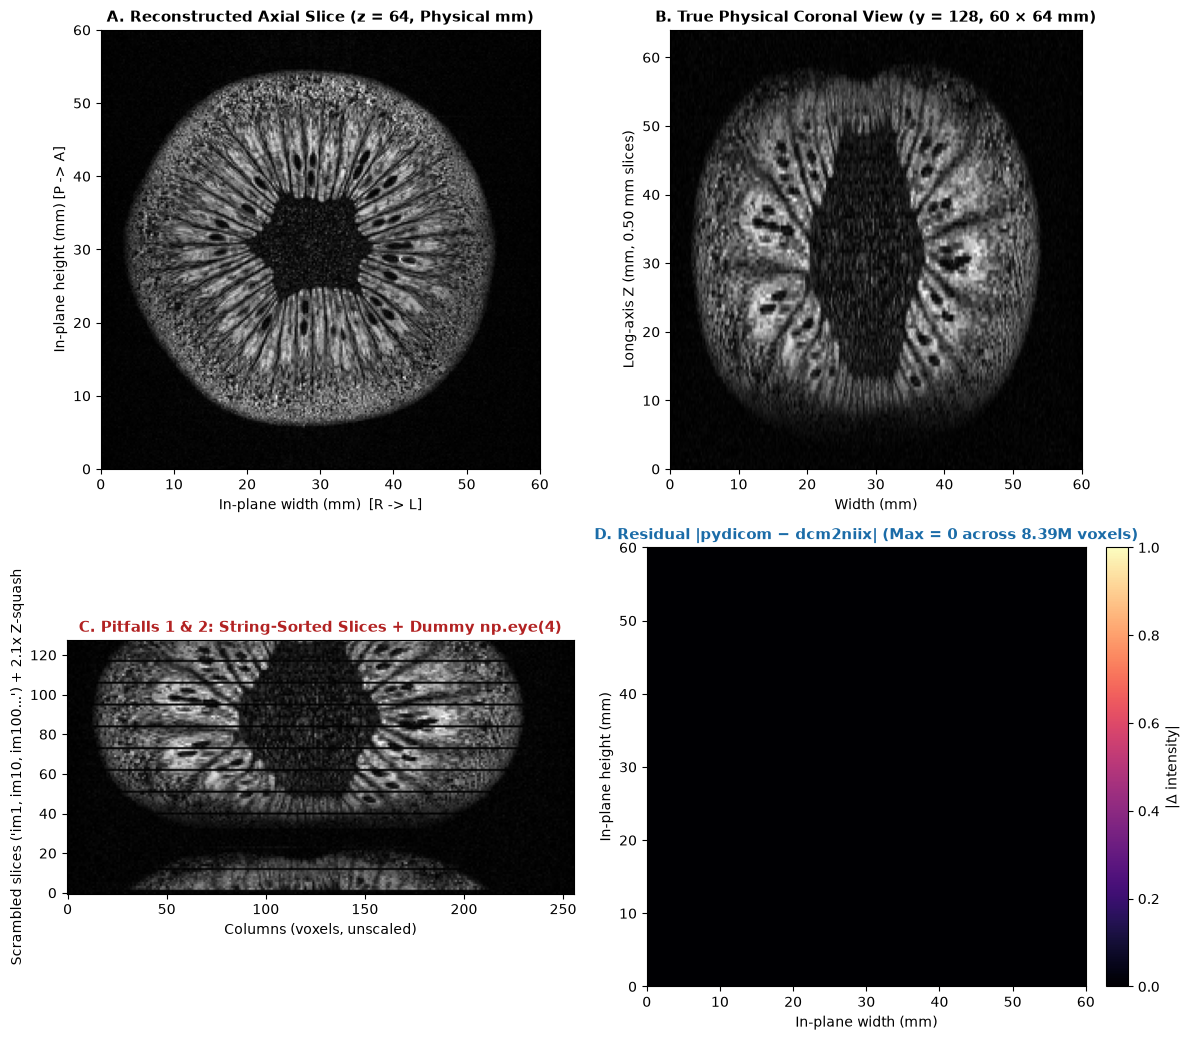

In [6]:
# Simulate Pitfall 1: What happens when non-zero-padded filenames ("im1", "im2", ..., "im10", ..., "im100")
# are sorted alphabetically as strings instead of by ImagePositionPatient!
unpadded_order = sorted(range(len(dicom_paths)), key=lambda idx: f"im{idx + 1}.dcm")
scrambled_vol = wb_vol[:, :, unpadded_order]

# Quantify Pitfall 2: Whole-fruit volume under np.eye(4) (1.0 mm^3/voxel) vs true affine (0.02747 mm^3/voxel)
fruit_mask = wb_vol > 2500  # rough whole-fruit foreground mask above background noise
true_voxel_mm3 = float(np.abs(np.linalg.det(wb_affine[:3, :3])))
eye_voxel_mm3 = float(np.abs(np.linalg.det(np.eye(4)[:3, :3])))

true_fruit_cm3 = fruit_mask.sum() * true_voxel_mm3 / 1000.0
wrong_fruit_cm3 = fruit_mask.sum() * eye_voxel_mm3 / 1000.0

print(f"True voxel volume  (|det(affine)|) : {true_voxel_mm3:.5f} mm^3  ->  Estimated fruit volume = {true_fruit_cm3:6.1f} cm^3 (realistic kiwifruit)")
print(f"Dummy np.eye(4)    (|det(I_4)|)    : {eye_voxel_mm3:.5f} mm^3  ->  Estimated fruit volume = {wrong_fruit_cm3:6.1f} cm^3 ({wrong_fruit_cm3/true_fruit_cm3:.1f}x too large — watermelon-sized!)")

# 4-panel visual diagnostic
canon_wb = nib.as_closest_canonical(nib.Nifti1Image(wb_vol, wb_affine))
canon_wb_arr = np.asarray(canon_wb.dataobj)
canon_ref_arr = np.asarray(nib.as_closest_canonical(ref_nii).dataobj)
abs_diff_arr = np.abs(canon_wb_arr.astype(np.int32) - canon_ref_arr.astype(np.int32))

dx, dy, dz = ref_nii.header.get_zooms()[:3]
fov_x, fov_y, fov_z = wb_vol.shape[0] * dx, wb_vol.shape[1] * dy, wb_vol.shape[2] * dz

fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))

# Panel A: Physical axial slice z=64 in mm
ax = axes[0, 0]
ax.imshow(wb_vol[:, :, 64].T, cmap="gray", origin="lower", extent=[0, fov_x, 0, fov_y])
ax.set_title("A. Reconstructed Axial Slice (z = 64, Physical mm)", fontsize=11, fontweight="bold")
ax.set_xlabel("In-plane width (mm)  [R -> L]")
ax.set_ylabel("In-plane height (mm) [P -> A]")

# Panel B: True physical coronal aspect ratio (dz / dx = 0.50 / 0.2344 = 2.133)
ax = axes[0, 1]
ax.imshow(wb_vol[:, 128, :].T, cmap="gray", origin="lower", extent=[0, fov_x, 0, fov_z])
ax.set_title(f"B. True Physical Coronal View (y = 128, {fov_x:.0f} × {fov_z:.0f} mm)", fontsize=11, fontweight="bold")
ax.set_xlabel("Width (mm)")
ax.set_ylabel("Long-axis Z (mm, 0.50 mm slices)")

# Panel C: Pitfall 1 (Alphabetical filename sort on unpadded names + Pitfall 2 unscaled voxel aspect)
ax = axes[1, 0]
ax.imshow(scrambled_vol[:, 128, :].T, cmap="gray", origin="lower", aspect=1.0)
ax.set_title("C. Pitfalls 1 & 2: String-Sorted Slices + Dummy np.eye(4)", fontsize=11, fontweight="bold", color="#b22222")
ax.set_xlabel("Columns (voxels, unscaled)")
ax.set_ylabel("Scrambled slices ('im1, im10, im100...') + 2.1x Z-squash")

# Panel D: Exact verification residual (dcm2niix vs pydicom reconstruction)
ax = axes[1, 1]
im_diff = ax.imshow(abs_diff_arr[:, :, 64].T, cmap="magma", vmin=0, vmax=1, origin="lower", extent=[0, fov_x, 0, fov_y])
ax.set_title(f"D. Residual |pydicom − dcm2niix| (Max = {abs_diff_arr.max()} across 8.39M voxels)", fontsize=11, fontweight="bold", color="#1b6ca8")
ax.set_xlabel("In-plane width (mm)")
ax.set_ylabel("In-plane height (mm)")
plt.colorbar(im_diff, ax=ax, fraction=0.046, pad=0.04, label="|Δ intensity|")

plt.tight_layout()
plt.show()

### Interpreting the 4-Panel Conversion Diagnostic (Panels A–D)

1. **Panels A & B (True Physical Millimeter Geometry):** Using `extent=[0, fov_x, 0, fov_y]` and `[0, fov_x, 0, fov_z]` from the NIfTI header renders both the equatorial cross-section (`60 × 60 mm`) and the longitudinal coronal view (`60 × 64 mm`) at their **true ~1:1 biological proportions** — showing a plump, nearly spherical `'Hayward'` berry (`~52 mm` wide $\times$ `~52.5 mm` long).
2. **Panel C (Compound Catastrophe of Pitfalls 1 & 2):**
   - Sorting unpadded filenames alphabetically (`"im1", "im10", "im100", ..., "im2"`) shreds the longitudinal seed chambers into horizontal Venetian-blind stripes.
   - Simultaneously, omitting physical voxel zooms (`np.eye(4)`) squashes the `128` axial slices vertically by $0.50 / 0.234375 = \mathbf{2.133\times}$ and inflates foreground volume by $1 / 0.027466 = \mathbf{36.4\times}$ (`2,574.7 cm³` — the size of a watermelon!).
   - *Subtle cross-notebook preview:* Why did our rough intensity threshold `wb_vol > 2500` above estimate `70.7 cm³`, whereas Notebook `03` reports **`85.97 cm³`** for the whole kiwifruit? Look at the jet-black central *columella* and dark seeds inside Panel A: their $T_2$-weighted intensity is `< 2500`, so a raw threshold leaves `~15.3 cm³` of internal holes inside the fruit until 3D morphological hole-filling (`ndi.binary_fill_holes`) is applied in Notebook `03`!
3. **Panel D (Bit-Exact Verification):** After mapping both our white-box `pydicom` NIfTI and the reference `dcm2niix` NIfTI to canonical `RAS+` (`nib.as_closest_canonical`), the maximum absolute difference across all `8,388,608` voxels is **`0` (`0.00000000 mm` affine residual)**.

### Check Your Understanding: Affine Geometry & Storage Order

**Q2.** `SimpleITK` saved our scan with `axcodes = ('L', 'P', 'S')` and affine $y$-column $[0, -0.234375, 0, +33.5]^\top$, whereas `dcm2niix` flipped the `256` rows (`j' = 255 - j`, `axcodes = ('L', 'A', 'S')`) with $y$-column $[0, +0.234375, 0, -26.265625]^\top$. Verify algebraically that a seed at `SimpleITK` row `j = 55` (`j' = 200` in `dcm2niix`) maps to the **exact same `RAS+` world coordinate $y_{\text{RAS}}$** in both files!

<details>
<summary>Click to reveal answer</summary>

- **In `SimpleITK` (`j = 55`):** $y_{\text{RAS}} = -0.234375 \times 55 + 33.5 = -12.890625 + 33.5 = \mathbf{+20.609375\text{ mm}}$.
- **In `dcm2niix` (`j' = 255 - 55 = 200`):** $y_{\text{RAS}} = +0.234375 \times 200 - 26.265625 = 46.875 - 26.265625 = \mathbf{+20.609375\text{ mm}}$!
- Because the array row-flip and the affine origin/sign update cancel identically, any affine-aware tool (`nibabel`, `ITK-SNAP`, `3D Slicer`, `MONAI`) places the seed at the exact same physical millimeter location in space.

</details>

---

## Key Takeaways for Your Biomedical Imaging Projects

1. **Formats reflect history and purpose:** From custom C + `XITE/BIFF` (`<filename>.us`) pipelines on 12-bit 1.0 T scanners in the early 1990s, medical imaging converged on **DICOM** for clinical PACS interoperability and **NIfTI (`.nii.gz`) + BIDS (`.json`)** for de-identified 3D/4D quantitative research and AI.
2. **Never discard the affine or sort by filename:** Always order 2D slices using 3D `ImagePositionPatient` projected onto `ImageOrientationPatient`, and preserve anisotropic physical spacing (`0.2344 × 0.2344 × 0.5000 mm³`) so physical biomarkers ($V_{\text{kiwi}}$, seed volume in $\text{mm}^3$, and 3D filter scales) reflect reality rather than voxel counts.
3. **Different voxel storage orders (`LPS` vs. `LAS` vs. `RAS+`) are reconciled by the $4\times 4$ affine:** Tools like `SimpleITK` and `dcm2niix` may store rows in opposite directions on disk, yet encode the exact same 3D millimeter object when read through `nibabel` (`nib.as_closest_canonical`).
4. **Always inspect `.json` units & privacy before sharing data:** Converting to NIfTI strips `(0010, xxxx)` patient identity tags, while BIDS `.json` sidecars record `TE` and `TR` in **seconds** (whereas DICOM stores them in **milliseconds**).

---

### Where to Go Next in the Kiwi Challenge Sequence

- **Next → [`01-kiwi-explore.ipynb`](./01-kiwi-explore.ipynb):** Inspect the converted 3D NIfTI volume, header fields, orthogonal slices, and affine coordinate systems.
- **[`02-kiwi-seeds-explore.ipynb`](./02-kiwi-seeds-explore.ipynb):** 2D filtering, thresholding, K-means clustering & the 2011–2012 Dagstuhl/CUHK 3D variational milestone.
- **[`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb):** Full 3D segmentation ladder, MS-like "lesion load", Curated 3D Micro-GT scoring & the 4-Panel Semi-Verifiability Dashboard.
- **[`03b-kiwi-interactive-gt-and-interrater.ipynb`](./03b-kiwi-interactive-gt-and-interrater.ipynb):** Interactive 3D Jupyter-Widget seed delineator, inter-rater variability, $\text{PQ}$ & STAPLE consensus.
- **[`04-kiwi-semantic-vs-instance.ipynb`](./04-kiwi-semantic-vs-instance.ipynb):** 3D PyTorch Semantic vs. Deep Distance/Flow Instance U-Nets & promptable foundation models.
- **[`05-kiwi-promptable-foundation-models.ipynb`](./05-kiwi-promptable-foundation-models.ipynb)** & **[`06-kiwi-frontier-ai-paradigms.ipynb`](./06-kiwi-frontier-ai-paradigms.ipynb):** Live `SAM 2.1`/`MedSAM` foundation models & pure-PyTorch frontier capstone (`3D SSL`, `3D U-Mamba`, Conditional Diffusion, & Neurosymbolic `LTN`) with printable guides in [`../docs/`](../docs/promptable-foundation-models.md).
- **Lab 5 Bridge ([`Lab5-Comp-Mod/Kiwi-challenge`](../../../Lab5-Comp-Mod/Kiwi-challenge/README.md)):** Mechanistic ODE/PDE morphogenesis models & a generative **3D Bloch-MRI Digital Twin** built from these exact `TR`/`TE` and voxel-geometry parameters!